In [1]:
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
%matplotlib qt

file_path = "ensemble_de_donnees/eau/lkq_eau.edf"
raw_eeg = mne.io.read_raw_edf(file_path, preload=True)

eeg_channels = ["AF3", "F7", "F3", "FC5", "T7", "P7", "O1", "O2", "P8", "T8", "FC6", "F4", "F8", "AF4"]
raw_eeg.pick(eeg_channels)

montage = mne.channels.make_standard_montage("standard_1020")
raw_eeg.set_montage(montage)

Extracting EDF parameters from ensemble_de_donnees/eau/lkq_eau.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 13439  =      0.000 ...   104.992 secs...


<RawEDF | lkq_eau.edf, 14 x 13440 (105.0 s), ~1.5 MiB, data loaded>

In [3]:
ica = mne.preprocessing.ICA(n_components=14, random_state=42)
ica.fit(raw_eeg)

Fitting ICA to data using 14 channels (please be patient, this may take a while)
Selecting by number: 14 components


/tmp/ipykernel_3174311/2438755403.py:2: RuntimeWarning: The data has not been high-pass filtered. For good ICA performance, it should be high-pass filtered (e.g., with a 1.0 Hz lower bound) before fitting ICA.
  ica.fit(raw_eeg)


Fitting ICA took 0.2s.


Method,fastica
Fit parameters,algorithm=parallelfun=logcoshfun_args=Nonemax_iter=1000
Fit,13 iterations on raw data (13440 samples)
ICA components,14
Available PCA components,14
Channel types,eeg
ICA components marked for exclusion,—


In [4]:
ica.plot_properties(raw_eeg, picks=0)

    Using multitaper spectrum estimation with 7 DPSS windows
Not setting metadata
52 matching events found
No baseline correction applied
0 projection items activated


[<Figure size 700x600 with 6 Axes>]

Using EOG channel: F7
... filtering ICA sources
Setting up band-pass filter from 1 - 10 Hz

FIR filter parameters
---------------------
Designing a two-pass forward and reverse, zero-phase, non-causal bandpass filter:
- Windowed frequency-domain design (firwin2) method
- Hann window
- Lower passband edge: 1.00
- Lower transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 0.75 Hz)
- Upper passband edge: 10.00 Hz
- Upper transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 10.25 Hz)
- Filter length: 1280 samples (10.000 s)

... filtering target
Setting up band-pass filter from 1 - 10 Hz

FIR filter parameters
---------------------
Designing a two-pass forward and reverse, zero-phase, non-causal bandpass filter:
- Windowed frequency-domain design (firwin2) method
- Hann window
- Lower passband edge: 1.00
- Lower transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 0.75 Hz)
- Upper passband edge: 10.00 Hz
- Upper transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 10.25 Hz)
- F

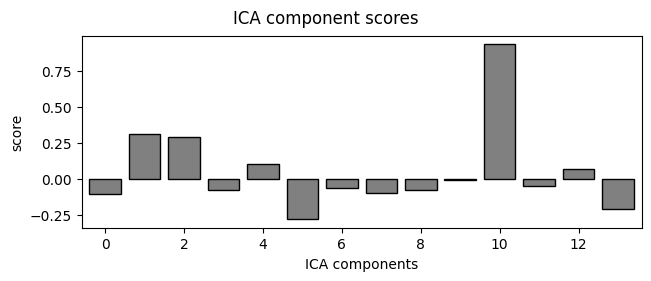

In [5]:
eog_indices, eog_scores = ica.find_bads_eog(raw_eeg, ch_name="F7")
ica.plot_scores(eog_scores)

In [13]:
import mne
import numpy as np
import matplotlib.pyplot as plt

def visualize_ica_artefact_rejection(raw, ica, channel_name='F7', component_idx=0, time_range=(0, 10)):
    """
    Visualizes single-channel EEG signal, ICA scalp topography, and component scores
    for simple artifact rejection decision-making.

    Parameters
    ----------
    raw : mne.io.Raw
        The preprocessed EEG data.
    ica : mne.preprocessing.ICA
        The fitted ICA object.
    channel_name : str
        EEG channel name to inspect (e.g., 'F7', 'AF3').
    component_idx : int
        Index of the ICA component to inspect.
    time_range : tuple
        Time window (tmin, tmax) in seconds to display on the channel plot.
    """
    # 1. Create subplots layout
    fig = plt.figure(figsize=(14, 8), constrained_layout=True)
    gs = fig.add_gridspec(2, 2, height_ratios=[1, 1], width_ratios=[1.2, 1])

    ax_raw = fig.add_subplot(gs[0, :])       # Top: Single Channel EEG Trace
    ax_topo = fig.add_subplot(gs[1, 0])      # Bottom Left: ICA Topomap
    ax_score = fig.add_subplot(gs[1, 1])     # Bottom Right: Component Scores

    # Time indices
    tmin, tmax = time_range
    sfreq = raw.info['sfreq']
    start_idx = int(tmin * sfreq)
    stop_idx = int(tmax * sfreq)
    times = raw.times[start_idx:stop_idx]

    # --- Panel 1: Single Channel Raw vs. ICA-Cleaned Signal ---
    raw_data = raw.get_data(picks=channel_name)[0, start_idx:stop_idx] * 1e6  # Convert V to µV
    
    # Plot raw channel trace
    ax_raw.plot(times, raw_data, label=f'Raw {channel_name} (Before ICA)', color='crimson', alpha=0.7, lw=1.2)
    
    # If any components are excluded in ICA, show the reconstructed clean trace overlay
    if len(ica.exclude) > 0:
        raw_clean = ica.apply(raw.copy(), verbose=False)
        clean_data = raw_clean.get_data(picks=channel_name)[0, start_idx:stop_idx] * 1e6
        ax_raw.plot(times, clean_data, label=f'Clean {channel_name} (After ICA)', color='navy', lw=1.5)

    ax_raw.set_title(f"1. Raw EEG Trace — Channel: {channel_name}", fontsize=12, fontweight='bold')
    ax_raw.set_xlabel("Time (s)")
    ax_raw.set_ylabel("Amplitude (µV)")
    ax_raw.legend(loc="upper right")
    ax_raw.grid(True, linestyle="--", alpha=0.5)

    # --- Panel 2: ICA Topographic Map ---
    mne.viz.plot_ica_components(ica, picks=component_idx, axes=ax_topo, show=False)
    ax_topo.set_title(f"2. ICA Component {component_idx} Topography", fontsize=12, fontweight='bold')

    # --- Panel 3: Artifact Score Across Components ---
    # Find EOG artifact correlation scores using frontal channels
    eog_indices, eog_scores = ica.find_bads_eog(raw, ch_name=channel_name, verbose=False)
    n_comps = ica.n_components_
    comp_indices = np.arange(n_comps)
    
    # Color bad components red, selected component orange, and normal components blue
    colors = []
    for i in comp_indices:
        if i in ica.exclude or i in eog_indices:
            colors.append('crimson')
        else:
            colors.append('steelblue')
            
    bars = ax_score.bar(comp_indices, np.abs(eog_scores), color=colors, alpha=0.85, edgecolor='black')
    
    ax_score.set_title(f"3. ICA Artifact Scores (EOG Detection on {channel_name})", fontsize=12, fontweight='bold')
    ax_score.set_xlabel("ICA Component Index")
    ax_score.set_ylabel("Absolute Correlation Score")
    ax_score.set_xticks(comp_indices)
    ax_score.grid(axis='y', linestyle='--', alpha=0.5)

    plt.show()


In [16]:
visualize_ica_artefact_rejection(
    raw=raw_eeg, 
    ica=ica, 
    channel_name='F7', 
    component_idx=0, 
    time_range=(5, 15)
)
